# Crypto correlations, constrained Kelly, and portfolio metrics

This notebook updates the local price history with the latest CoinGecko observations before calculating correlations, constrained Kelly weights, and portfolio metrics. It excludes ETH and SOL and analyzes BTC, BAT, VVV, NEAR, ZEC, GRT, AAVE, AERO, and HYPE.

At run time, choose a CoinGecko Demo or Pro API plan and enter its API key. The key is requested with hidden input and is not saved in the notebook.

The portfolio uses constrained full Kelly with long-only bounds of 2% minimum and 15% maximum per coin. These user-selected bounds ensure each asset is represented and limit concentration; any unallocated share is cash.

Portfolio statistics use BTC as the market benchmark, a 0% annual risk-free rate, and 365 trading days per year. Change these assumptions in the metrics cell if desired.

### Refresh prices from CoinGecko

Fetch recent USD price observations for each selected coin using your Demo API key, then save the updated price history for the analysis below.

In [ ]:
# Fetch recent observations for each coin before loading prices for analysis.
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
from getpass import getpass
import requests

api_plan = 'demo'  # This notebook uses a CoinGecko Demo API key.
api_key = getpass('CoinGecko API key (input hidden): ').strip()
if not api_key:
    raise ValueError('A CoinGecko API key is required.')
api_host = 'api.coingecko.com' if api_plan == 'demo' else 'pro-api.coingecko.com'
api_header = 'x-cg-demo-api-key' if api_plan == 'demo' else 'x-cg-pro-api-key'
headers = {api_header: api_key}

PRICE_FILE = Path('crypto_daily_prices_usd.csv')
COIN_IDS = {
    'BTC': 'bitcoin',
    'BAT': 'basic-attention-token',
    'VVV': 'venice-token',
    'NEAR': 'near',
    'ZEC': 'zcash',
    'GRT': 'the-graph',
    'AAVE': 'aave',
    'AERO': 'aerodrome-finance',
    'HYPE': 'hyperliquid',
}
END_DATE = datetime.now(timezone.utc)
prices = pd.read_csv(PRICE_FILE, parse_dates=['date'])
prices['date'] = pd.to_datetime(prices['date'], utc=True).dt.normalize()
prices = prices.set_index('date').sort_index()

for ticker, coin_id in COIN_IDS.items():
    if ticker not in prices.columns:
        prices[ticker] = pd.NA
    saved = pd.to_numeric(prices[ticker], errors='coerce').dropna()
    start_date = (saved.index.max() - pd.Timedelta(days=1)).to_pydatetime() if not saved.empty else datetime(2025, 10, 1, tzinfo=timezone.utc)
    start_date = start_date.replace(hour=0, minute=0, second=0, microsecond=0)
    url = f'https://{api_host}/api/v3/coins/{coin_id}/market_chart/range'
    params = {'vs_currency': 'usd', 'from': int(start_date.timestamp()), 'to': int(END_DATE.timestamp()), 'interval': 'daily'}
    response = requests.get(url, params=params, headers=headers, timeout=30)
    response.raise_for_status()
    data = response.json()
    if 'prices' not in data:
        raise ValueError(f'{ticker}: CoinGecko response did not contain prices: {data}')
    fetched = pd.DataFrame(data['prices'], columns=['timestamp_ms', ticker])
    if fetched.empty:
        latest = saved.index.max().date() if not saved.empty else 'none'
        print(f'{ticker}: no newer observations (latest saved: {latest})')
        continue
    fetched['date'] = pd.to_datetime(fetched.pop('timestamp_ms'), unit='ms', utc=True).dt.normalize()
    updates = fetched.drop_duplicates('date', keep='last').set_index('date')[ticker]
    prices = prices.reindex(prices.index.union(updates.index)).sort_index()
    prices.loc[updates.index, ticker] = updates
    print(f'{ticker}: refreshed {len(updates)} observations from {updates.index.min().date()} through {updates.index.max().date()}')

prices = prices.sort_index()
prices.to_csv(PRICE_FILE, date_format='%Y-%m-%dT%H:%M:%SZ')
#print(f'Updated {PRICE_FILE}; analysis will use this refreshed price history.')

BTC: refreshed 2 observations from 2026-10-15 through 2026-10-16
BAT: refreshed 2 observations from 2026-10-15 through 2026-10-16
VVV: refreshed 2 observations from 2026-10-15 through 2026-10-16
NEAR: refreshed 2 observations from 2026-10-15 through 2026-10-16
ZEC: refreshed 2 observations from 2026-10-15 through 2026-10-16
GRT: refreshed 2 observations from 2026-10-15 through 2026-10-16
AAVE: refreshed 2 observations from 2026-10-15 through 2026-10-16
AERO: refreshed 2 observations from 2026-10-15 through 2026-10-16
HYPE: refreshed 2 observations from 2026-10-15 through 2026-10-16
Updated crypto_daily_prices_usd.csv; analysis will use this refreshed price history.


### Load the refreshed price history

Read the price CSV updated by the CoinGecko fetch cell, check that all selected assets are present, and prepare the price table for analysis.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.optimize import minimize

PRICE_FILE = Path('crypto_daily_prices_usd.csv')
ASSETS = ['BTC', 'BAT', 'VVV', 'NEAR', 'ZEC', 'GRT', 'AAVE', 'AERO', 'HYPE']

if not PRICE_FILE.exists():
    raise FileNotFoundError(f'Missing saved price file: {PRICE_FILE.resolve()}')
prices = pd.read_csv(PRICE_FILE, parse_dates=['date']).set_index('date').sort_index()
prices.index = pd.to_datetime(prices.index, utc=True).normalize()

missing = [ticker for ticker in ASSETS if ticker not in prices.columns]
if missing:
    raise ValueError(f'Missing saved price columns: {missing}')
prices = prices[ASSETS].apply(pd.to_numeric, errors='coerce').sort_index()
#prices.tail()

,BTC,BAT,VVV,NEAR,ZEC,GRT,AAVE,AERO,HYPE
date,,,,,,,,,
2026-10-12 00:00:00+00:00,83690.869232,0.159889,24.691664,5.887577,1275.571031,0.028094,171.515383,0.943219,86.619963
2026-10-13 00:00:00+00:00,81794.848817,0.153653,22.359656,5.086170,1166.913215,0.025434,156.838025,0.876497,80.966606
2026-10-14 00:00:00+00:00,83115.101596,0.197103,22.722411,5.036516,1217.901339,0.026140,160.302202,0.903437,81.526642
2026-10-15 00:00:00+00:00,81603.654646,0.172254,23.238010,4.881085,1146.777997,0.025159,154.335614,0.903372,80.810141
2026-10-16 00:00:00+00:00,82155.539797,0.215791,24.756746,5.257478,1220.527705,0.025120,157.430976,0.936831,81.706524


### Calculate daily returns and correlations

Compute daily percentage returns for the assets, keep dates with complete data, and display their Pearson correlation matrix.

In [3]:
returns = prices.pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
common_returns = returns.dropna(subset=ASSETS)
if len(common_returns) < 30:
    raise ValueError(f'Only {len(common_returns)} common daily returns; need at least 30.')
#correlation = common_returns.corr(method='pearson')
#display(correlation.round(3))
#print(f'Common sample: {common_returns.index.min().date()} to {common_returns.index.max().date()} ({len(common_returns)} daily returns)')

### Optional correlation heatmap

Uncomment this cell to display the daily return correlation matrix as a heatmap.

In [4]:
# fig, ax = plt.subplots(figsize=(10, 8))
# sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0, square=True, ax=ax)
# ax.set_title('Daily return correlations')
# plt.tight_layout()
# plt.show()

## Constrained full-Kelly portfolio

The optimizer maximizes historical daily log growth subject to the per-asset bounds, with any unallocated share held as cash. The chart, period returns, and performance metrics below all use these constrained full-Kelly weights.

In [ ]:
MIN_FULL_KELLY_WEIGHT = 0.02
MAX_FULL_KELLY_WEIGHT = 0.15
RISK_FREE_ANNUAL = 0.00
TRADING_DAYS_PER_YEAR = 365
R = common_returns[ASSETS].to_numpy(dtype=float)
n_assets = len(ASSETS)
RISK_FREE_DAILY = (1 + RISK_FREE_ANNUAL) ** (1 / TRADING_DAYS_PER_YEAR) - 1

def negative_log_growth(w):
    port_ret = R @ w + (1.0 - w.sum()) * RISK_FREE_DAILY
    if np.any(port_ret <= -1):
        return 1e12
    return -np.log1p(port_ret).mean()

result = minimize(
    negative_log_growth,
    x0=np.full(n_assets, 1.0 / n_assets),
    method='SLSQP',
    bounds=[(MIN_FULL_KELLY_WEIGHT, MAX_FULL_KELLY_WEIGHT)] * n_assets,
    constraints=[{'type': 'ineq', 'fun': lambda w: 1.0 - w.sum()}],
    options={'maxiter': 5000, 'ftol': 1e-12},
)
if not result.success:
    raise RuntimeError(f'Kelly optimization failed: {result.message}')
full_kelly = pd.Series(result.x, index=ASSETS, name='weight')
full_portfolio = full_kelly.copy()
full_portfolio.loc['Cash'] = 1.0 - full_kelly.sum()
# print('Constrained full-Kelly weights (%)')
# display((100 * full_portfolio).rename('weight_pct').round(2).to_frame())

Constrained full-Kelly weights (%)


,weight_pct
BTC,2.0
BAT,15.0
VVV,15.0
NEAR,15.0
ZEC,15.0
GRT,2.0
AAVE,6.0
AERO,15.0
HYPE,15.0
Cash,0.0


## Constrained full-Kelly portfolio performance metrics

Sharpe ratio and volatility are annualized using 365 days per year. Expected return is the annualized arithmetic mean. Alpha is annualized CAPM alpha versus BTC. Max drawdown is the largest peak-to-trough decline in the portfolio's compounded daily value.

### Calculate portfolio returns and performance

Apply the optimized weights, compare the portfolio with BTC, and calculate trailing returns, drawdown, and annualized risk and return metrics.

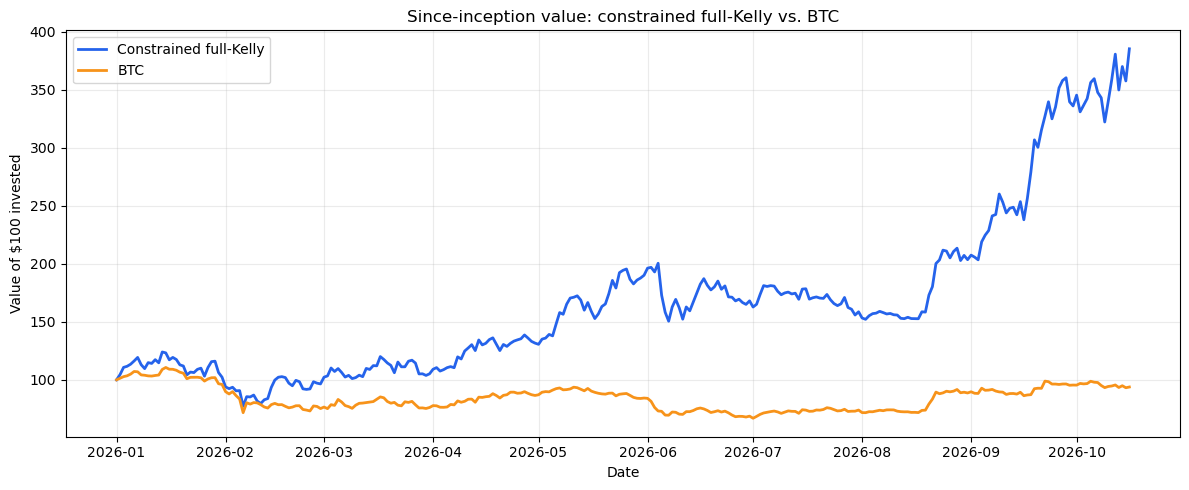

,Return
1D,7.75%
7D,19.58%
M (1 month),61.92%
Q (3 months),115.89%
Since Inception,285.38%


,Daily return
Average daily return,0.55%
Largest daily gain,11.41%
Largest daily loss,-14.81%


Portfolio value shown from 2026-01-01 through 2026-10-16 (latest saved observation).


,All-Time High ($),Minimum Portfolio Value ($),Max Drawdown ($),Max Drawdown (%)
Since inception,$385.38,$77.27,-$49.94,-37.69%


,Sharpe,Beta,Alpha,Expected Return,Volatility,Risk-Free Rate,Max Drawdown
Constrained full-Kelly,2.615,1.164,198.28%,200.72%,76.75%,0.00%,-37.69%


Benchmark: BTC; period: 2026-01-02 to 2026-10-16


In [6]:
BENCHMARK = 'BTC'
if BENCHMARK not in common_returns.columns:
    raise ValueError(f'Benchmark {BENCHMARK} is not in the return data.')

risky_weights = full_kelly.reindex(ASSETS).to_numpy()
portfolio_daily_returns = pd.Series(
    common_returns[ASSETS].to_numpy() @ risky_weights
    + full_portfolio.loc['Cash'] * RISK_FREE_DAILY,
    index=common_returns.index,
    name='Portfolio',
)
benchmark_returns = common_returns[BENCHMARK]
excess_returns = portfolio_daily_returns - RISK_FREE_DAILY
benchmark_excess = benchmark_returns - RISK_FREE_DAILY

beta = portfolio_daily_returns.cov(benchmark_returns) / benchmark_returns.var(ddof=1)
annualized_expected_return = portfolio_daily_returns.mean() * TRADING_DAYS_PER_YEAR
annualized_volatility = portfolio_daily_returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)
sharpe = (excess_returns.mean() / portfolio_daily_returns.std(ddof=1)) * np.sqrt(TRADING_DAYS_PER_YEAR)
alpha = (excess_returns.mean() - beta * benchmark_excess.mean()) * TRADING_DAYS_PER_YEAR
wealth = (1 + portfolio_daily_returns).cumprod()
initial_value = 100.0
initial_date = common_returns.index[0] - pd.Timedelta(days=1)
portfolio_value = pd.concat([
    pd.Series([initial_value], index=pd.DatetimeIndex([initial_date])),
    initial_value * wealth,
])
portfolio_value.name = 'Portfolio value ($)'
btc_wealth = (1 + benchmark_returns).cumprod()
btc_value = pd.concat([
    pd.Series([initial_value], index=pd.DatetimeIndex([initial_date])),
    initial_value * btc_wealth,
])
btc_value.name = 'BTC value ($)'

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(portfolio_value.index, portfolio_value, color='#2563eb', linewidth=2, label='Constrained full-Kelly')
ax.plot(btc_value.index, btc_value, color='#F7931A', linewidth=2, label='BTC')
ax.set_title('Since-inception value: constrained full-Kelly vs. BTC')
ax.set_ylabel('Value of $100 invested')
ax.set_xlabel('Date')
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

as_of = portfolio_value.index[-1]
def trailing_return(days=None, months=None):
    target = as_of - (pd.DateOffset(months=months) if months is not None else pd.Timedelta(days=days))
    prior = portfolio_value.loc[portfolio_value.index <= target]
    if prior.empty:
        return np.nan
    return portfolio_value.iloc[-1] / prior.iloc[-1] - 1

period_returns = pd.Series({
    '1D': trailing_return(days=1),
    '7D': trailing_return(days=7),
    'M (1 month)': trailing_return(months=1),
    'Q (3 months)': trailing_return(months=3),
    'Since Inception': portfolio_value.iloc[-1] / 100 - 1
}, name='Return')
display(period_returns.to_frame().style.format('{:.2%}', na_rep='N/A'))
daily_return_summary = pd.Series({
    'Average daily return': portfolio_daily_returns.mean(),
    'Largest daily gain': portfolio_daily_returns.max(),
    'Largest daily loss': portfolio_daily_returns.min(),
}, name='Daily return')
display(daily_return_summary.to_frame().style.format('{:.2%}'))
print(f'Portfolio value shown from {portfolio_value.index[0].date()} through {as_of.date()} (latest saved observation).')
portfolio_peak = portfolio_value.cummax()
drawdown = portfolio_value / portfolio_peak - 1
drawdown_dollars = portfolio_value - portfolio_peak
max_drawdown = drawdown.min()
investment_summary = pd.Series({
    'All-Time High ($)': portfolio_value.max(),
    'Minimum Portfolio Value ($)': portfolio_value.min(),
    'Max Drawdown ($)': drawdown_dollars.min(),
    'Max Drawdown (%)': max_drawdown,
}, name='Since inception')
display(investment_summary.to_frame().T.style.format({
    'All-Time High ($)': '${:,.2f}',
    'Minimum Portfolio Value ($)': '${:,.2f}',
    'Max Drawdown ($)': lambda value: f'-${abs(value):,.2f}' if value < 0 else f'${value:,.2f}',
    'Max Drawdown (%)': '{:.2%}',
}))
risk_free_annual = (1 + RISK_FREE_DAILY) ** TRADING_DAYS_PER_YEAR - 1

performance_metrics = pd.DataFrame([{
    'Sharpe': sharpe,
    'Beta': beta,
    'Alpha': alpha,
    'Expected Return': annualized_expected_return,
    'Volatility': annualized_volatility,
    'Risk-Free Rate': risk_free_annual,
    'Max Drawdown': max_drawdown,
}], index=['Constrained full-Kelly'])
display(performance_metrics.style.format({
    'Sharpe': '{:.3f}', 'Beta': '{:.3f}', 'Alpha': '{:.2%}',
    'Expected Return': '{:.2%}', 'Volatility': '{:.2%}',
    'Risk-Free Rate': '{:.2%}', 'Max Drawdown': '{:.2%}',
}))
print(f'Benchmark: {BENCHMARK}; period: {common_returns.index.min().date()} to {common_returns.index.max().date()}')

### Save analysis outputs

Write the refreshed prices, daily returns, correlation matrix, optimized weights, portfolio returns, and performance metrics to CSV files.

In [7]:
#correlation.to_csv('crypto_return_correlation.csv')
full_portfolio.to_csv('crypto_kelly_full_weights.csv', header=True)
full_portfolio.to_csv('crypto_kelly_weights.csv', header=True)
performance_metrics.to_csv('crypto_portfolio_metrics.csv')
portfolio_daily_returns.to_csv('crypto_portfolio_daily_returns.csv', header=True)
prices.to_csv('crypto_daily_prices_usd.csv')
common_returns.to_csv('crypto_daily_returns.csv')
print('Saved correlation, Kelly weights, portfolio metrics, prices, and returns.')

NameError: name 'correlation' is not defined